Język: [English](examples.en.ipynb) | **Polski**

# Wykład 06 — eksperyment: filtry, mapy cech, CNN kontra MLP

Materiał towarzyszący [`lecture.md`](lecture.md). Dwa eksperymenty: (A)
mechanika konwolucji — ręczny przykład, filtry na syntetycznym obrazie,
stride/padding, pooling, filtr wyuczony vs. ręczny; (B) kontrolowane
porównanie CNN i MLP na Fashion-MNIST (accuracy, liczba parametrów, czas).


In [1]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")


Używane urządzenie: cpu


## A.1 Przykład rozwiązany: ręczna konwolucja kontra `nn.Conv2d`

Te same liczby, co w wykładzie — obraz $5\times5$, filtr $3\times3$
(detektor pionowej krawędzi), bez paddingu, stride $1$.


In [2]:
X = torch.tensor([
    [1., 2., 3., 0., 1.],
    [0., 1., 2., 3., 1.],
    [1., 0., 1., 2., 0.],
    [2., 1., 0., 1., 3.],
    [0., 2., 1., 0., 1.],
])
K = torch.tensor([
    [1., 0., -1.],
    [1., 0., -1.],
    [1., 0., -1.],
])


def manual_cross_correlation(img, kernel, stride=1, padding=0):
    if padding > 0:
        img = torch.nn.functional.pad(img, (padding, padding, padding, padding))
    H, W = img.shape
    kH, kW = kernel.shape
    out_h = (H - kH) // stride + 1
    out_w = (W - kW) // stride + 1
    out = torch.zeros(out_h, out_w)
    for i in range(out_h):
        for j in range(out_w):
            region = img[i * stride : i * stride + kH, j * stride : j * stride + kW]
            out[i, j] = (region * kernel).sum()
    return out


Y_manual = manual_cross_correlation(X, K)
print("Y (wzor reczny):")
print(Y_manual)

conv_check = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    conv_check.weight[:] = K.unsqueeze(0).unsqueeze(0)
Y_torch = conv_check(X.unsqueeze(0).unsqueeze(0)).squeeze().detach()
print("\nY (nn.Conv2d):")
print(Y_torch)

assert torch.allclose(Y_manual, Y_torch, atol=1e-6)
print("\nOK: wzor reczny zgadza sie z nn.Conv2d w granicach tolerancji numerycznej (atol=1e-6).")


Y (wzor reczny):
tensor([[-4., -2.,  4.],
        [ 0., -4., -1.],
        [ 1.,  0., -2.]])

Y (nn.Conv2d):
tensor([[-4., -2.,  4.],
        [ 0., -4., -1.],
        [ 1.,  0., -2.]])

OK: wzor reczny zgadza sie z nn.Conv2d w granicach tolerancji numerycznej (atol=1e-6).


## A.2 Filtry na syntetycznym obrazie

Jasny kwadrat $6\times6$ na ciemnym tle $12\times12$. Sprawdzamy, co
filtry *faktycznie* wykrywają — nie zakładamy tego z góry.


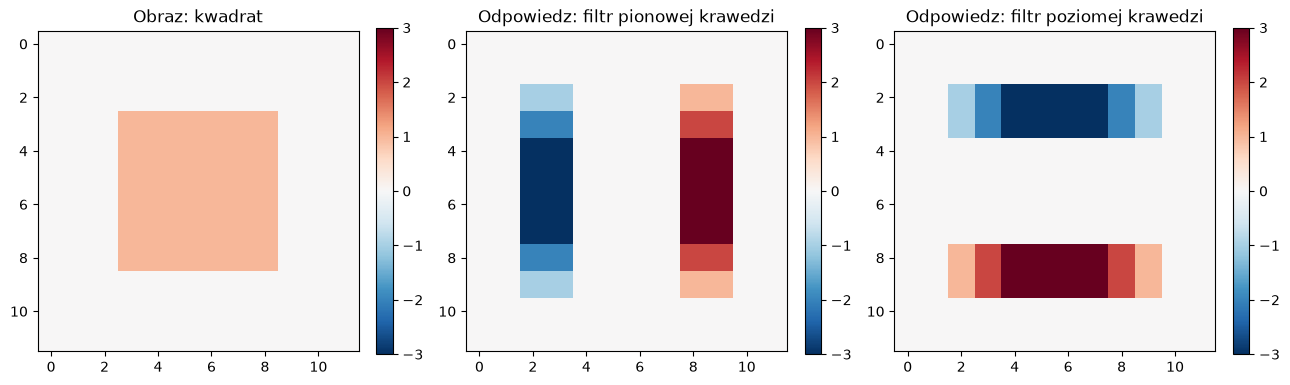

Odpowiedz filtra pionowego, srodkowy wiersz: [0.0, 0.0, -3.0, -3.0, 0.0, 0.0, 0.0, 0.0, 3.0, 3.0, 0.0, 0.0]
Odpowiedz filtra poziomego, srodkowa kolumna: [0.0, 0.0, -3.0, -3.0, 0.0, 0.0, 0.0, 0.0, 3.0, 3.0, 0.0, 0.0]


In [3]:
square_img = torch.zeros(12, 12)
square_img[3:9, 3:9] = 1.0

vertical_edge = torch.tensor([[1., 0., -1.], [1., 0., -1.], [1., 0., -1.]])
horizontal_edge = torch.tensor([[1., 1., 1.], [0., 0., 0.], [-1., -1., -1.]])


def apply_filter(img, kernel, stride=1, padding=1):
    conv = nn.Conv2d(1, 1, kernel_size=kernel.shape[0], stride=stride, padding=padding, bias=False)
    with torch.no_grad():
        conv.weight[:] = kernel.unsqueeze(0).unsqueeze(0)
    return conv(img.unsqueeze(0).unsqueeze(0)).squeeze().detach()


v_response = apply_filter(square_img, vertical_edge)
h_response = apply_filter(square_img, horizontal_edge)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (title, data) in zip(
    axes,
    [
        ("Obraz: kwadrat", square_img),
        ("Odpowiedz: filtr pionowej krawedzi", v_response),
        ("Odpowiedz: filtr poziomej krawedzi", h_response),
    ],
):
    im = ax.imshow(data, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

print("Odpowiedz filtra pionowego, srodkowy wiersz:", v_response[6].tolist())
print("Odpowiedz filtra poziomego, srodkowa kolumna:", h_response[:, 6].tolist())


## A.3 Stride i padding


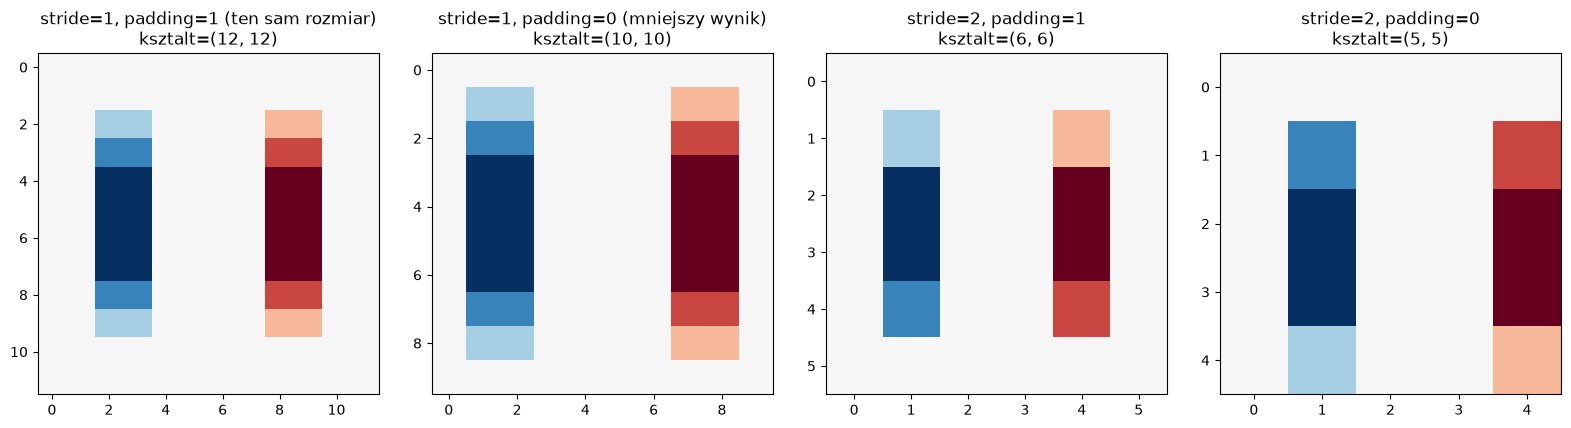

OK: dla wszystkich czterech konfiguracji ksztalt wyjscia zgadza sie ze wzorem.


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
configs = [
    ("stride=1, padding=1 (ten sam rozmiar)", 1, 1),
    ("stride=1, padding=0 (mniejszy wynik)", 1, 0),
    ("stride=2, padding=1", 2, 1),
    ("stride=2, padding=0", 2, 0),
]
for ax, (title, stride, padding) in zip(axes, configs):
    response = apply_filter(square_img, vertical_edge, stride=stride, padding=padding)
    formula_size = (12 + 2 * padding - 3) // stride + 1
    assert response.shape[0] == formula_size, "wzor na rozmiar wyjscia sie nie zgadza!"
    im = ax.imshow(response, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(f"{title}\nksztalt={tuple(response.shape)}")
plt.tight_layout()
plt.show()
print("OK: dla wszystkich czterech konfiguracji ksztalt wyjscia zgadza sie ze wzorem.")


## A.4 Max pooling


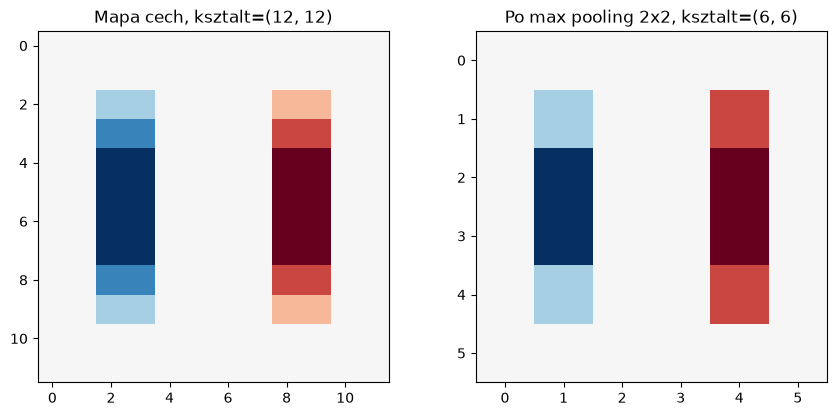

In [5]:
pool = nn.MaxPool2d(kernel_size=2)
v_response_full = apply_filter(square_img, vertical_edge, stride=1, padding=1)
pooled = pool(v_response_full.unsqueeze(0).unsqueeze(0)).squeeze()

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(v_response_full, cmap="RdBu_r", vmin=-3, vmax=3)
axes[0].set_title(f"Mapa cech, ksztalt={tuple(v_response_full.shape)}")
axes[1].imshow(pooled, cmap="RdBu_r", vmin=-3, vmax=3)
axes[1].set_title(f"Po max pooling 2x2, ksztalt={tuple(pooled.shape)}")
plt.tight_layout()
plt.show()


## A.5 Filtr ręczny kontra filtr wyuczony

Trenujemy pojedynczą warstwę `Conv2d` tak, żeby jej wyjście pasowało do
wyjścia znanego filtra (pionowej krawędzi) na losowych obrazach — sprawdzamy,
czy trening faktycznie odtworzy ten filtr, czy coś innego.


In [6]:
torch.manual_seed(0)
random_imgs = torch.rand(200, 1, 12, 12)

target_conv = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)
with torch.no_grad():
    target_conv.weight[:] = vertical_edge.unsqueeze(0).unsqueeze(0)
targets = target_conv(random_imgs).detach()

learned_conv = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)
opt = torch.optim.Adam(learned_conv.parameters(), lr=0.05)
loss_fn = nn.MSELoss()
for epoch in range(300):
    opt.zero_grad()
    pred = learned_conv(random_imgs)
    loss = loss_fn(pred, targets)
    loss.backward()
    opt.step()

print(f"strata koncowa: {loss.item():.2e}")
print("\nfiltr prawdziwy (pionowa krawedz):")
print(vertical_edge)
print("\nfiltr wyuczony:")
print(learned_conv.weight.detach().squeeze().round(decimals=3))


strata koncowa: 7.07e-13

filtr prawdziwy (pionowa krawedz):
tensor([[ 1.,  0., -1.],
        [ 1.,  0., -1.],
        [ 1.,  0., -1.]])

filtr wyuczony:
tensor([[ 1.,  0., -1.],
        [ 1.,  0., -1.],
        [ 1.,  0., -1.]])


## B. CNN kontra MLP na Fashion-MNIST

Dane pobierane automatycznie (torchvision), nigdy nie zapisywane w repo.
Podzbiór $8000$ treningowych / $2000$ testowych dla szybkości na CPU.


X_train=(8000, 1, 28, 28)  X_test=(2000, 1, 28, 28)
klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


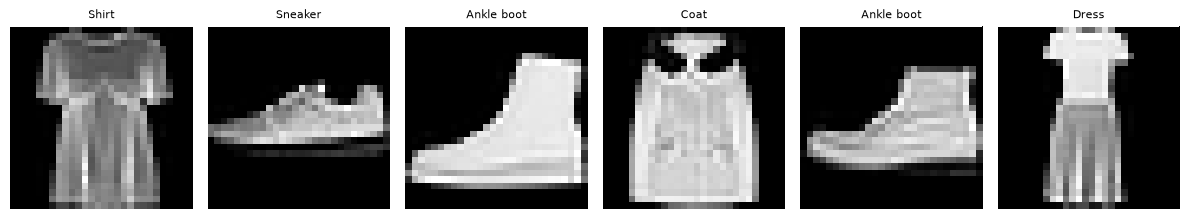

In [7]:
import os
from pathlib import Path

_REPO_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "pyproject.toml").is_file()),
    Path.cwd(),
)
DATA_CACHE_DIR = Path(
    os.environ.get("DEEP_LEARNING_DATA_CACHE", _REPO_ROOT / "data_cache")
).expanduser().resolve()

import contextlib
import io

# Pobieranie wypisuje postep (pasek tqdm, domyslnie na stderr) co kilka
# procent; w notebooku to tylko szum, wiec wyciszamy oba strumienie
# tutaj (sam pobierany plik i jego MD5 sa weryfikowane przez
# torchvision niezaleznie od tego, co wypisuje na ekran).
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    train_ds = torchvision.datasets.FashionMNIST(
        root=DATA_CACHE_DIR, train=True, download=True, transform=T.ToTensor()
    )
    test_ds = torchvision.datasets.FashionMNIST(
        root=DATA_CACHE_DIR, train=False, download=True, transform=T.ToTensor()
    )

N_TRAIN, N_TEST = 8000, 2000
split_gen = torch.Generator().manual_seed(0)
train_idx = torch.randperm(len(train_ds), generator=split_gen)[:N_TRAIN]
test_idx = torch.randperm(len(test_ds), generator=split_gen)[:N_TEST]

X_train = torch.stack([train_ds[i][0] for i in train_idx]).to(device)
y_train = torch.tensor([train_ds[i][1] for i in train_idx]).to(device)
X_test = torch.stack([test_ds[i][0] for i in test_idx]).to(device)
y_test = torch.tensor([test_ds[i][1] for i in test_idx]).to(device)
class_names = train_ds.classes

print(f"X_train={tuple(X_train.shape)}  X_test={tuple(X_test.shape)}")
print("klasy:", class_names)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.2))
for ax, i in zip(axes, range(6)):
    ax.imshow(X_train[i, 0].cpu(), cmap="gray")
    ax.set_title(class_names[y_train[i].item()], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [8]:
class MLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 10),
        )

    def forward(self, x):
        return self.net(x)


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.flatten(1)
        return self.fc(x)


def train_eval(model_cls, epochs, lr=0.001, batch_size=64, seed=0):
    torch.manual_seed(seed)
    model = model_cls().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    n = X_train.shape[0]

    start = time.time()
    for epoch in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            opt.zero_grad()
            out = model(X_train[idx])
            loss = loss_fn(out, y_train[idx])
            loss.backward()
            opt.step()
    train_time = time.time() - start

    model.eval()
    start = time.time()
    with torch.no_grad():
        test_logits = model(X_test)
    infer_time = time.time() - start
    test_acc = (test_logits.argmax(1) == y_test).float().mean().item()
    with torch.no_grad():
        train_acc = (model(X_train).argmax(1) == y_train).float().mean().item()

    n_params = sum(p.numel() for p in model.parameters())
    return model, {
        "train_acc": train_acc,
        "test_acc": test_acc,
        "train_time_s": train_time,
        "infer_time_s": infer_time,
        "n_params": n_params,
    }


In [9]:
results = {"MLP": [], "CNN": []}
models = {}
for seed in [0, 1, 2]:
    mlp_model, mlp_res = train_eval(MLP, epochs=10, seed=seed)
    cnn_model, cnn_res = train_eval(SmallCNN, epochs=10, seed=seed)
    results["MLP"].append(mlp_res)
    results["CNN"].append(cnn_res)
    if seed == 0:
        models["MLP"] = mlp_model
        models["CNN"] = cnn_model
    m_acc, m_t = mlp_res["test_acc"], mlp_res["train_time_s"]
    c_acc, c_t = cnn_res["test_acc"], cnn_res["train_time_s"]
    print(f"seed={seed}  MLP: test_acc={m_acc:.3f} train_time={m_t:.2f}s"
          f"   CNN: test_acc={c_acc:.3f} train_time={c_t:.2f}s")

print()
for name, runs in results.items():
    accs = [r["test_acc"] for r in runs]
    times = [r["train_time_s"] for r in runs]
    infer = [r["infer_time_s"] for r in runs]
    n_params = runs[0]["n_params"]
    acc_line = f"{name}: params={n_params}  test_acc={sum(accs) / 3:.3f}"
    acc_line += f" (min={min(accs):.3f} max={max(accs):.3f})"
    time_line = f"  train_time~{sum(times) / 3:.2f}s  infer_time~{sum(infer) / 3 * 1000:.1f}ms"
    print(acc_line + time_line)


seed=0  MLP: test_acc=0.836 train_time=0.78s   CNN: test_acc=0.860 train_time=11.66s


seed=1  MLP: test_acc=0.851 train_time=0.75s   CNN: test_acc=0.832 train_time=11.66s


seed=2  MLP: test_acc=0.851 train_time=0.76s   CNN: test_acc=0.864 train_time=11.96s

MLP: params=118282  test_acc=0.846 (min=0.836 max=0.851)  train_time~0.76s  infer_time~0.5ms
CNN: params=20490  test_acc=0.852 (min=0.832 max=0.864)  train_time~11.76s  infer_time~29.1ms


## Wybrane filtry i mapy cech wytrenowanej CNN

Patrzymy na to, co faktycznie widać — bez nadinterpretacji.


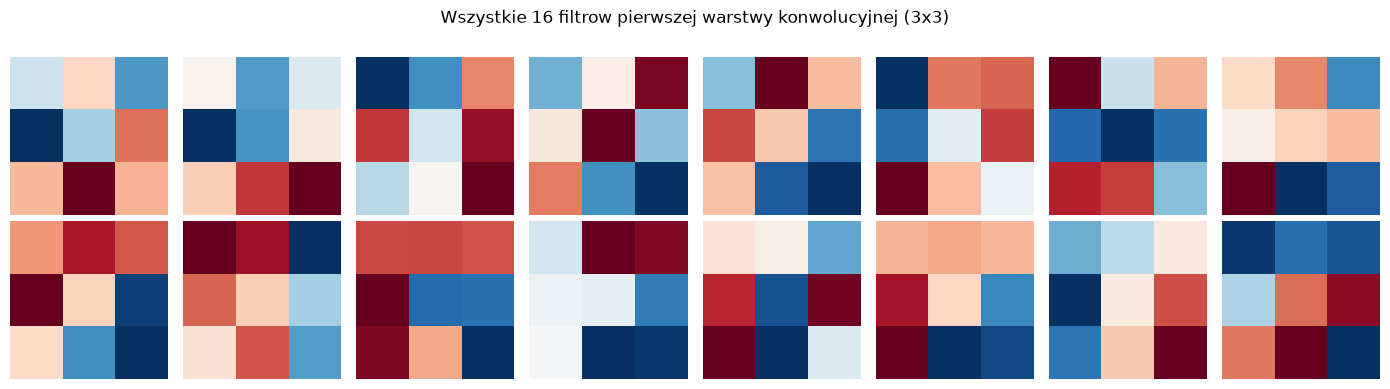

In [10]:
cnn = models["CNN"]
first_layer_filters = cnn.conv1.weight.detach().cpu()  # (16, 1, 3, 3)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(first_layer_filters[i, 0], cmap="RdBu_r")
    ax.axis("off")
fig.suptitle("Wszystkie 16 filtrow pierwszej warstwy konwolucyjnej (3x3)")
plt.tight_layout()
plt.show()


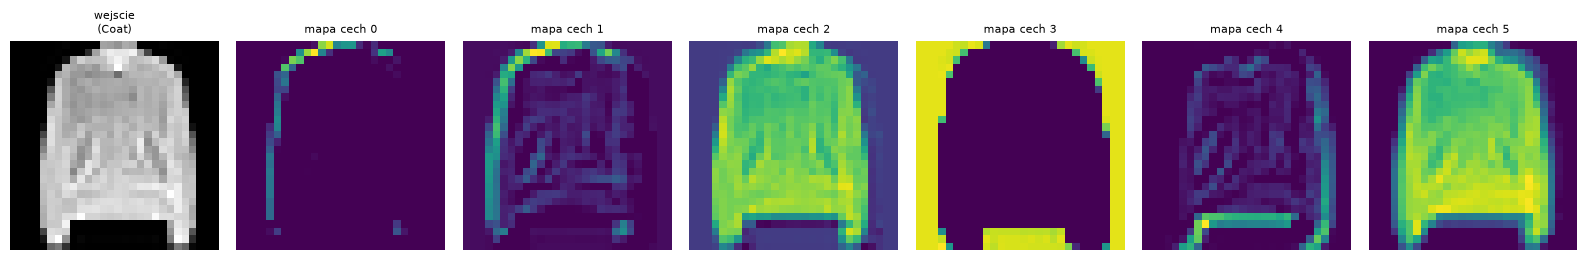

Co widac: niektore mapy reaguja silnie na konkretne krawedzie/kontury obiektu, inne wygladaja na mniej czytelne/bardziej rozproszone. Czego NIE mozna stad wiarygodnie stwierdzic: ze dany filtr 'rozpoznaje' konkretna czesc ubioru - to wymagaloby dalszej, systematycznej analizy, nie pojedynczego obrazu.


In [11]:
sample_img = X_test[0:1]
with torch.no_grad():
    feature_maps = torch.relu(cnn.conv1(sample_img))  # (1, 16, 28, 28)

fig, axes = plt.subplots(1, 7, figsize=(16, 2.5))
axes[0].imshow(sample_img[0, 0].cpu(), cmap="gray")
axes[0].set_title(f"wejscie\n({class_names[y_test[0].item()]})", fontsize=8)
axes[0].axis("off")
for i, ax in enumerate(axes[1:]):
    ax.imshow(feature_maps[0, i].cpu(), cmap="viridis")
    ax.set_title(f"mapa cech {i}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

print(
    "Co widac: niektore mapy reaguja silnie na konkretne krawedzie/kontury "
    "obiektu, inne wygladaja na mniej czytelne/bardziej rozproszone. Czego "
    "NIE mozna stad wiarygodnie stwierdzic: ze dany filtr 'rozpoznaje' "
    "konkretna czesc ubioru - to wymagaloby dalszej, systematycznej analizy, "
    "nie pojedynczego obrazu."
)


## Podsumowanie

- Ręczny wzór na konwolucję zgadza się z `nn.Conv2d` w granicach tolerancji
  numerycznej (`atol=1e-6`); wzory na rozmiar wyjścia i liczbę parametrów
  zweryfikowane analogicznie (plik testowy, nie ta komórka -- zobacz
  `lecture.md`).
- Filtry faktycznie wykrywają to, co przewiduje matematyka (zero
  wewnątrz/na zewnątrz kwadratu, silna odpowiedź dokładnie na krawędziach)
  — zmierzone, nie założone.
- Wyuczony filtr, dla dobrze postawionego zadania, odtworzył prawdziwy
  filtr niemal dokładnie.
- CNN pobiła MLP nieznacznie pod względem accuracy przy $5{,}8\times$
  mniej parametrach — ale trenowała się na CPU $\approx15\times$ wolniej.
  Mniej parametrów $\neq$ mniej obliczeń.

Pytania do dyskusji i bibliografia: zobacz [`lecture.md`](lecture.md).
